# Water Quality Potability & Hydro-Chemical Contamination Analyzer
## Deliverable A: Engineering Development Cycle Notebook (Phases 1–5)
This notebook documents our iterative exploration, mathematical verification, OOP unit assertions, statistical modeling, and visualization prototyping.

### Phase 1: Exploratory Data Ingestion & Diagnostics

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
from src.ingestion import audit_and_clean_csv, WaterPotabilityAuditor

raw_csv = '../data/raw/water_potability_raw.csv'
clean_csv = '../data/processed/clean_water_potability.csv'
audit_log = '../data/processed/water_ingestion_audit.log'

audit_summary = audit_and_clean_csv(raw_csv, clean_csv, audit_log, check_who=False)
print('phase 1 ingestion audit:', audit_summary)

phase 1 ingestion audit: {'total_records': 3276, 'valid_records': 3276, 'rejected_records': 0, 'violations': {'corrupted_or_non_numeric': 0, 'ph_out_of_bounds': 0, 'negative_chemical': 0, 'invalid_potability': 0, 'who_limit_exceeded': 0}}


### Phase 2: Mathematical Formulation & Feature Verification (`np.allclose`)

In [2]:
from src.analyzer import load_and_prepare_data, compute_vectorized_wqi

df_raw, df_clean = load_and_prepare_data(clean_csv)
wqi_out = compute_vectorized_wqi(df_clean)

assert wqi_out['allclose_verified'] is True, 'vectorized wqi mismatch!'
print('phase 2 np.allclose verification passed | mean wqi:', wqi_out['mean_wqi'])

phase 2 np.allclose verification passed | mean wqi: 49.0252


### Phase 3: OOP Class Architecture & Automated Unit Assertions

In [3]:
auditor = WaterPotabilityAuditor()
count = auditor.load_from_csv(clean_csv)
assert count == 3276, f'expected 3276 rows, got {count}'

# unit test 1: negative weights must raise ValueError
try:
    auditor.compute_wqi(weights=[-1, 1, 1, 1, 1, 1, 1, 1, 1])
    raise AssertionError('negative weights did not raise ValueError')
except ValueError as err:
    print('unit test passed (negative weights caught):', err)

# unit test 2: wrong weight vector length must raise ValueError
try:
    auditor.compute_wqi(weights=[0.5, 0.5])
    raise AssertionError('wrong length weights did not raise ValueError')
except ValueError as err:
    print('unit test passed (wrong length caught):', err)

print('auditor summary:', auditor.summary_report())

unit test passed (negative weights caught): weights cannot contain negative values
unit test passed (wrong length caught): weights must be a 1d sequence of length 9
auditor summary: {'total_samples': 3276, 'potable_samples': 1278, 'non_potable_samples': 1998, 'potable_ratio': 0.3901, 'missing_values': {'ph': 491, 'Hardness': 0, 'Solids': 0, 'Chloramines': 0, 'Sulfate': 781, 'Conductivity': 0, 'Organic_carbon': 0, 'Trihalomethanes': 162, 'Turbidity': 0}}


### Phase 4: Statistical Modeling, Rolling Windows & Regimen Exploration

In [4]:
from src.analyzer import (
    detect_who_and_zscore_anomalies,
    fit_solids_ols_plane,
    audit_missing_and_imputation,
    build_risk_pivot_table,
    extract_top_concentrations_long
)

df_clean['wqi_score'] = wqi_out['wqi_scores']
df_clean['wqi_rolling_50'] = df_clean['wqi_score'].rolling(window=50, min_periods=1).mean()

print('q5 anomalies:', detect_who_and_zscore_anomalies(df_clean))
print('q6 ols plane:', fit_solids_ols_plane(df_clean))
display(audit_missing_and_imputation(df_raw))
display(build_risk_pivot_table(df_clean))
_, top5 = extract_top_concentrations_long(df_clean, top_n=5)
display(top5.head(15))

q5 anomalies: {'who_violation_count': 1610, 'zscore_outlier_count': 148, 'intersection_count': 106, 'intersection_sample_ids': [37, 61, 66, 80, 88, 104, 140, 263, 275, 278, 283, 285, 287, 304, 317, 321, 335, 342, 345, 347, 351, 354, 365, 366, 379, 382, 383, 385, 434, 492, 531, 546, 692, 726, 781, 783, 785, 810, 951, 990, 1031, 1068, 1073, 1106, 1123, 1156, 1186, 1303, 1316, 1343, 1353, 1366, 1412, 1542, 1554, 1743, 1773, 1784, 1798, 1860, 1955, 2057, 2075, 2096, 2134, 2156, 2189, 2236, 2318, 2336, 2343, 2350, 2370, 2401, 2446, 2470, 2497, 2646, 2681, 2694, 2699, 2704, 2757, 2853, 2861, 2868, 2895, 2899, 2921, 2925, 2928, 2945, 2949, 3014, 3017, 3020, 3042, 3088, 3094, 3142, 3150, 3162, 3179, 3190, 3221, 3269]}
q6 ols plane: {'b0_intercept': 23866.2385, 'b1_conductivity': 1.3796, 'b2_hardness': -12.4263, 'residual_variance': 76753161.3, 'r2': 0.002361, 'pearson_r': 0.048592}


,parameter,missing_count,missing_pct,global_imputed_std,class_imputed_std,mean_abs_diff
0,ph,491,14.99,1.4700,1.4700,0.0001
1,Hardness,0,0.00,32.8798,32.8798,0.0000
2,Solids,0,0.00,8768.5708,8768.5708,0.0000
3,Chloramines,0,0.00,1.5831,1.5831,0.0000
4,Sulfate,781,23.84,36.1439,36.1468,0.1575
5,Conductivity,0,0.00,80.8241,80.8241,0.0000
6,Organic_carbon,0,0.00,3.3082,3.3082,0.0000
7,Trihalomethanes,162,4.95,15.7700,15.7699,0.0036
8,Turbidity,0,0.00,0.7804,0.7804,0.0000


Turbidity_Tier,Clear (<3),Moderate (3-5),Turbid (>5),Overall_Mean
pH_Regime,,,,
Acidic (<6.5),0.3762,0.3681,0.3578,0.3678
Neutral (6.5-8.5),0.4000,0.4188,0.4314,0.4178
Alkaline (>8.5),0.3125,0.3485,0.2308,0.3313
Overall_Mean,0.3781,0.3939,0.3726,0.3901


,Sample_ID,Chemical_Parameter,Value
0,351,Chloramines,13.127000
1,275,Chloramines,13.043806
2,287,Chloramines,12.912187
3,2694,Chloramines,12.653362
4,2336,Chloramines,12.626900
5,2704,Conductivity,753.342620
6,2134,Conductivity,708.226364
7,342,Conductivity,695.369528
8,3142,Conductivity,674.443476
9,140,Conductivity,672.556999


### Phase 5: Visual Prototype Development & Interactive Dashboard Export

displaying primary_envelope:


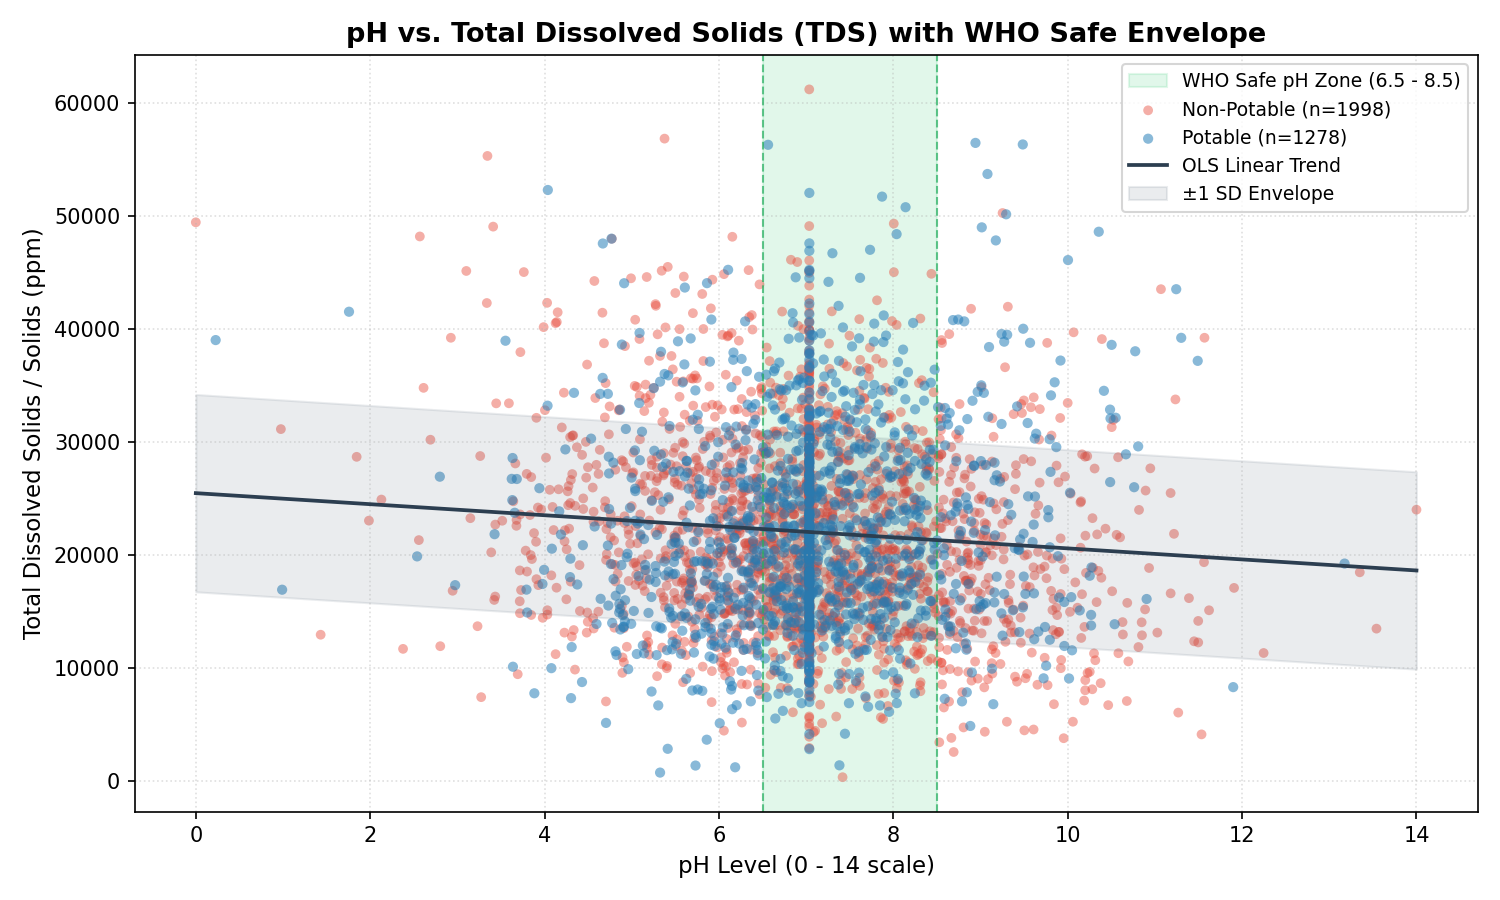

displaying correlation_heatmap:


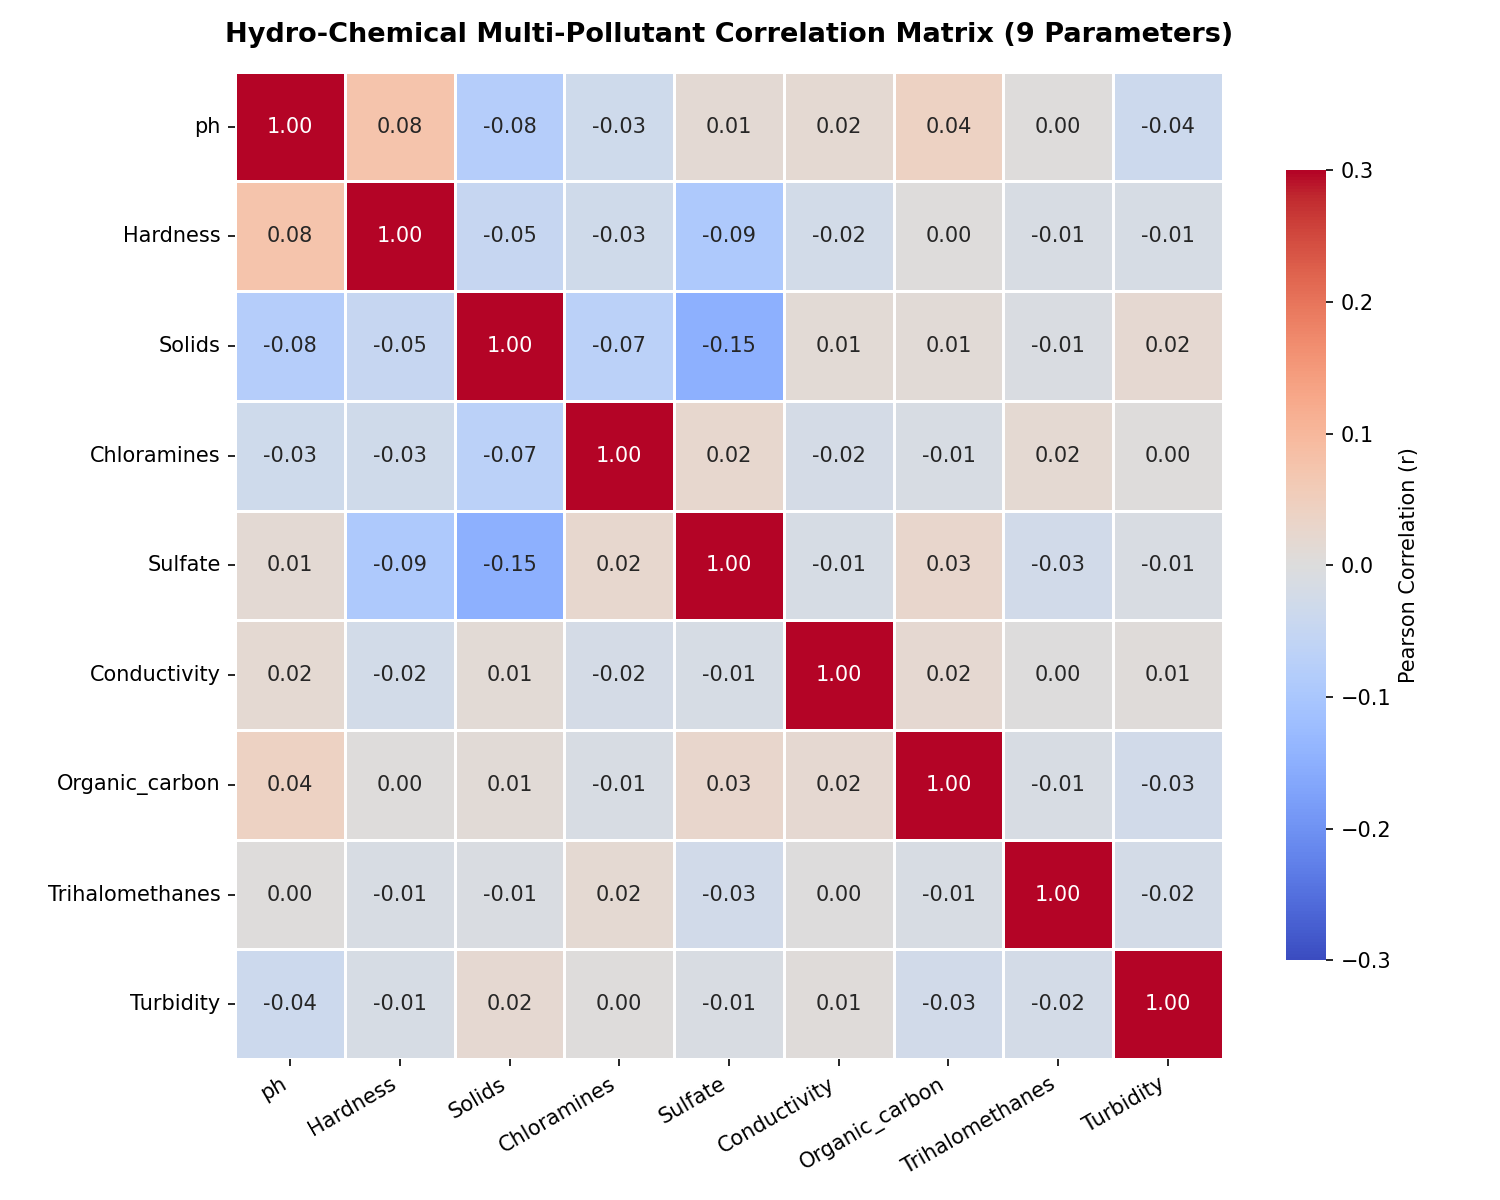

displaying distribution_regimes:


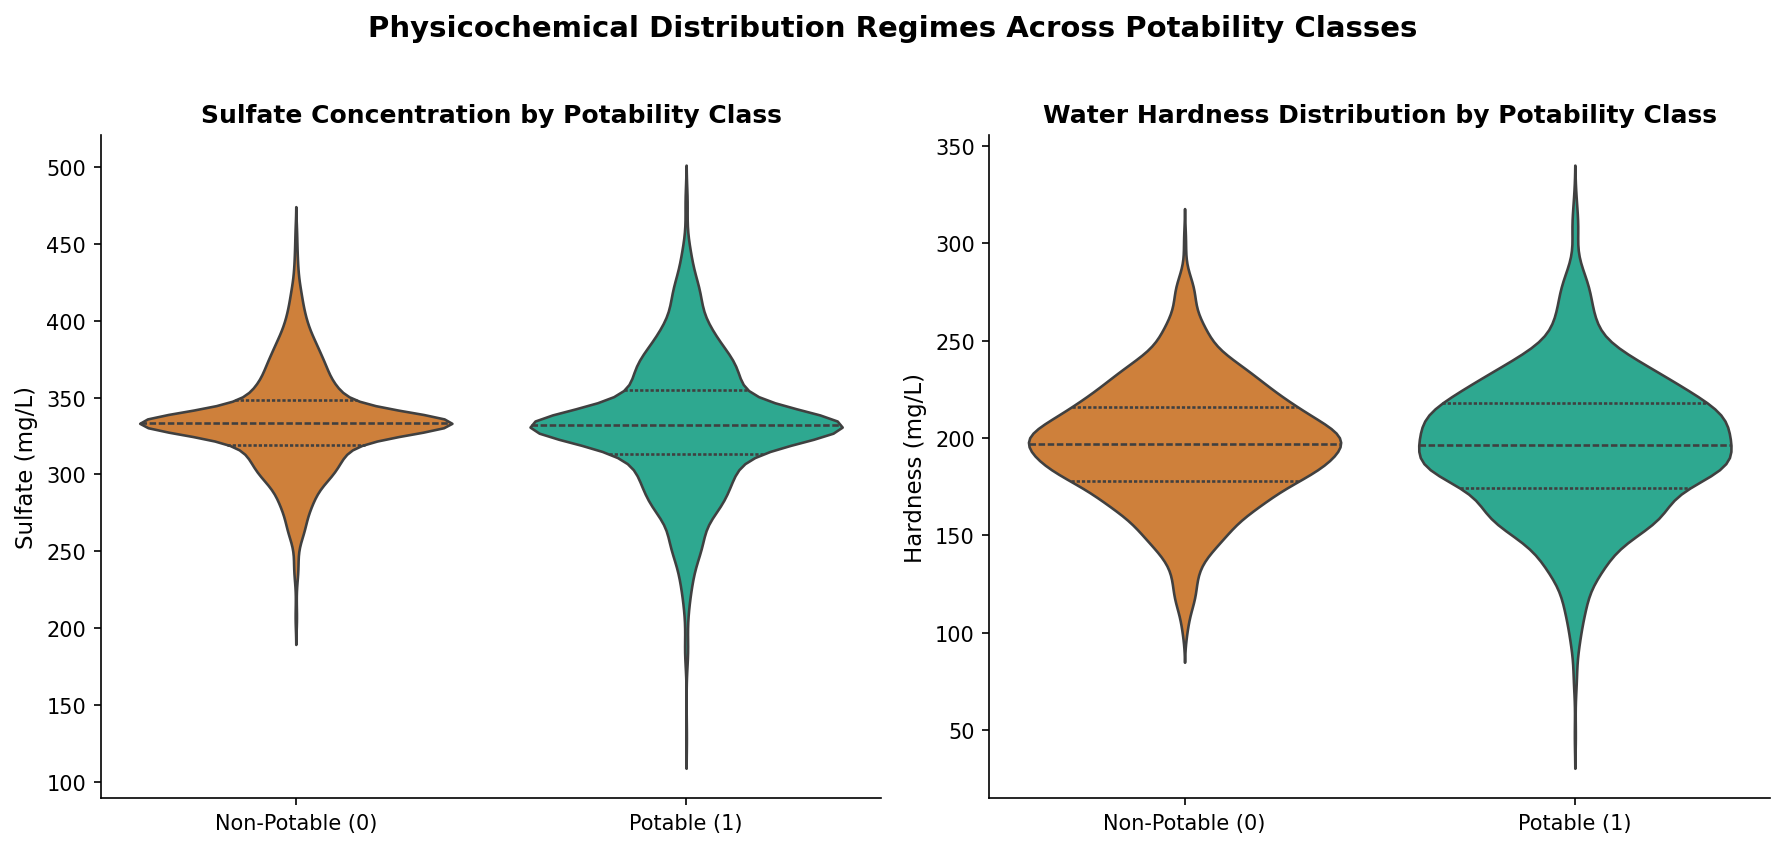

In [5]:
from src.visualizer import generate_all_visuals
from IPython.display import Image, display

paths = generate_all_visuals(df_clean, '../reports')
for label, img_path in paths.items():
    if img_path.endswith('.png'):
        print(f'displaying {label}:')
        display(Image(filename=img_path))